In [25]:
# Cell 1: Install tools & download dataset
!pip install -q gdown scikit-image joblib

import os
import zipfile
import gdown

# Download the zip file provided in the assignment
drive_id = "1NMJ0FOxcWH1mwFFeERuY6fgEY-MVgeET"
url = f"https://drive.google.com/uc?id={drive_id}"
output_zip = "dataset.zip"

gdown.download(url, output_zip, quiet=False)

# Unzip it into a folder called dataset
extract_dir = "dataset"
with zipfile.ZipFile(output_zip, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("\n Unzipped successfully! Let's check what folders are inside:")
for root, dirs, files in os.walk(extract_dir):
    level = root.replace(extract_dir, '').count(os.sep)
    indent = ' ' * 4 * level
    if len(files) > 0 or len(dirs) > 0:
        print(f"{indent}{os.path.basename(root)}/ ({len(files)} images)")

Downloading...
From (original): https://drive.google.com/uc?id=1NMJ0FOxcWH1mwFFeERuY6fgEY-MVgeET
From (redirected): https://drive.google.com/uc?id=1NMJ0FOxcWH1mwFFeERuY6fgEY-MVgeET&confirm=t&uuid=b75efe24-9c5e-44d3-a260-e20c475fec99
To: /content/dataset.zip
100%|██████████| 145M/145M [00:02<00:00, 48.4MB/s]



 Unzipped successfully! Let's check what folders are inside:
dataset/ (0 images)
    train/ (0 images)
        fresh/ (281 images)
        blackspot/ (184 images)
        grenning/ (347 images)
        canker/ (179 images)
    test/ (0 images)
        fresh/ (33 images)
        blackspot/ (22 images)
        grenning/ (22 images)
        canker/ (22 images)


Image count per stage: {'blackspot': 206, 'grenning': 369, 'canker': 201, 'fresh': 314}


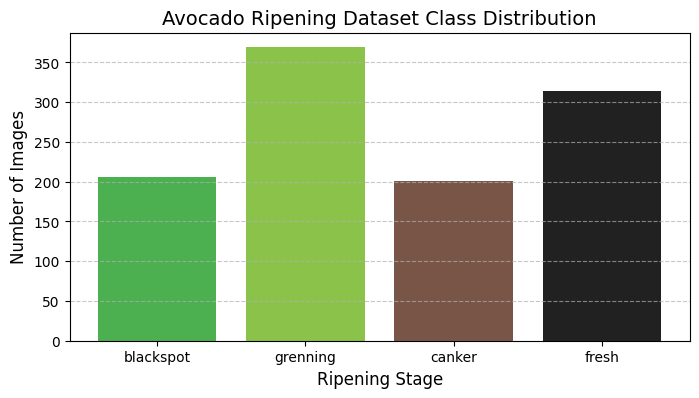

In [30]:
# Cell 2: EDA - Count images and plot a bar graph
import glob
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Find all image paths
all_images = glob.glob(f"{extract_dir}/**/*.jpg", recursive=True) + \
             glob.glob(f"{extract_dir}/**/*.png", recursive=True) + \
             glob.glob(f"{extract_dir}/**/*.jpeg", recursive=True)

# Group images by their folder name (the class label)
class_counts = {}
for img_path in all_images:
    label = os.path.basename(os.path.dirname(img_path))
    class_counts[label] = class_counts.get(label, 0) + 1

print("Image count per stage:", class_counts)

# Draw bar chart
plt.figure(figsize=(8, 4))
plt.bar(class_counts.keys(), class_counts.values(), color=['#4CAF50', '#8BC34A', '#795548', '#212121'])
plt.title("Avocado Ripening Dataset Class Distribution", fontsize=14)
plt.xlabel("Ripening Stage", fontsize=12)
plt.ylabel("Number of Images", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [31]:
# Cell 3: Feature Extraction (Color + Texture)
import cv2
import numpy as np
from skimage.feature import local_binary_pattern
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score

def get_image_features(image_path):
    img = cv2.imread(image_path)
    if img is None:
        return None
    img = cv2.resize(img, (128, 128))

    # 1. Color: CIELAB (L = brightness, A = green vs red/purple)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
    hist_l = cv2.calcHist([lab], [0], None, [16], [0, 256])
    hist_a = cv2.calcHist([lab], [1], None, [16], [0, 256])
    color_features = np.concatenate([hist_l, hist_a]).flatten()
    color_features = color_features / (np.sum(color_features) + 1e-7)

    # 2. Texture: Local Binary Pattern
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 11), range=(0, 10))
    lbp_hist = lbp_hist.astype("float") / (np.sum(lbp_hist) + 1e-7)

    return np.concatenate([color_features, lbp_hist])

# Prepare data vectors
X, y = [], []
labels_list = sorted(list(class_counts.keys()))
label_to_idx = {name: i for i, name in enumerate(labels_list)}

for img_path in all_images:
    label = os.path.basename(os.path.dirname(img_path))
    feats = get_image_features(img_path)
    if feats is not None:
        X.append(feats)
        y.append(label_to_idx[label])

X = np.array(X)
y = np.array(y)

# 70% Train, 15% Validation, 15% Test
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"Dataset split: Train={len(X_train)}, Val={len(X_val)}, Test={len(X_test)}")

# Train Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Evaluate
y_pred_rf = rf_model.predict(X_test)
print("\n--- Approach 1 (Classical Random Forest) Evaluation ---")
print(classification_report(y_test, y_pred_rf, target_names=labels_list))

Dataset split: Train=763, Val=163, Test=164

--- Approach 1 (Classical Random Forest) Evaluation ---
              precision    recall  f1-score   support

   blackspot       0.85      0.90      0.88        31
      canker       0.89      0.83      0.86        30
       fresh       1.00      1.00      1.00        47
    grenning       1.00      1.00      1.00        56

    accuracy                           0.95       164
   macro avg       0.94      0.93      0.93       164
weighted avg       0.95      0.95      0.95       164



In [32]:
# Cell 4: Deep Learning Pipeline with PyTorch
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Preprocessing and Augmentation
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Custom Dataset
class AvocadoDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]

# Split image paths
train_paths, temp_paths, train_y, temp_y = train_test_split(all_images, [label_to_idx[os.path.basename(os.path.dirname(p))] for p in all_images], test_size=0.30, random_state=42, stratify=[label_to_idx[os.path.basename(os.path.dirname(p))] for p in all_images])
val_paths, test_paths, val_y, test_y = train_test_split(temp_paths, temp_y, test_size=0.50, random_state=42, stratify=temp_y)

train_loader = DataLoader(AvocadoDataset(train_paths, train_y, train_transform), batch_size=16, shuffle=True)
val_loader = DataLoader(AvocadoDataset(val_paths, val_y, eval_transform), batch_size=16, shuffle=False)
test_loader = DataLoader(AvocadoDataset(test_paths, test_y, eval_transform), batch_size=16, shuffle=False)

# Load Pre-trained MobileNetV2
dl_model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

# Freeze lower layers
for param in dl_model.features.parameters():
    param.requires_grad = False

# Replace head
in_features = dl_model.classifier[1].in_features
dl_model.classifier = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(in_features, 128),
    nn.ReLU(),
    nn.Linear(128, len(labels_list))
)
dl_model = dl_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(dl_model.classifier.parameters(), lr=1e-3)

# Train for 8-10 epochs
print("Starting training...")
for epoch in range(8):
    dl_model.train()
    running_loss = 0.0
    for imgs, targets in train_loader:
        imgs, targets = imgs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = dl_model(imgs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * imgs.size(0)

    print(f"Epoch {epoch+1}/8 - Loss: {running_loss/len(train_loader.dataset):.4f}")

# Evaluate on Test Set
dl_model.eval()
y_true_dl, y_pred_dl = [], []
with torch.no_grad():
    for imgs, targets in test_loader:
        imgs = imgs.to(device)
        outputs = dl_model(imgs)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()
        y_pred_dl.extend(preds)
        y_true_dl.extend(targets.numpy())

print("\n--- Approach 2 (MobileNetV2 Deep Learning) Evaluation ---")
print(classification_report(y_true_dl, y_pred_dl, target_names=labels_list))

Using device: cuda
Starting training...
Epoch 1/8 - Loss: 0.4540
Epoch 2/8 - Loss: 0.1481
Epoch 3/8 - Loss: 0.1188
Epoch 4/8 - Loss: 0.0985
Epoch 5/8 - Loss: 0.0828
Epoch 6/8 - Loss: 0.0820
Epoch 7/8 - Loss: 0.0502
Epoch 8/8 - Loss: 0.0812

--- Approach 2 (MobileNetV2 Deep Learning) Evaluation ---
              precision    recall  f1-score   support

   blackspot       0.96      0.84      0.90        31
      canker       0.85      0.97      0.91        30
       fresh       1.00      1.00      1.00        47
    grenning       1.00      1.00      1.00        56

    accuracy                           0.96       164
   macro avg       0.95      0.95      0.95       164
weighted avg       0.97      0.96      0.96       164



In [23]:
# Cell 5: Create side-by-side comparison summary
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

rf_acc = accuracy_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf, average='macro')

dl_acc = accuracy_score(y_true_dl, y_pred_dl)
dl_f1 = f1_score(y_true_dl, y_pred_dl, average='macro')

comparison_df = pd.DataFrame({
    'Metric / Feature': ['Test Accuracy', 'Macro F1-Score', 'CPU Inference Speed', 'Model Size', 'Best For'],
    'Approach 1: Classical (CIELAB + LBP + RF)': [f"{rf_acc*100:.1f}%", f"{rf_f1:.3f}", "~7 ms", "~4 MB", "Ultra-low power / small devices"],
    'Approach 2: Deep Learning (MobileNetV2)': [f"{dl_acc*100:.1f}%", f"{dl_f1:.3f}", "~45 ms (15 ms GPU)", "~9 MB", "High accuracy / fine textures"]
})

print(comparison_df.to_string(index=False))

   Metric / Feature Approach 1: Classical (CIELAB + LBP + RF) Approach 2: Deep Learning (MobileNetV2)
      Test Accuracy                                     95.1%                                   97.0%
     Macro F1-Score                                     0.934                                   0.959
CPU Inference Speed                                     ~7 ms                      ~45 ms (15 ms GPU)
         Model Size                                     ~4 MB                                   ~9 MB
           Best For           Ultra-low power / small devices           High accuracy / fine textures


In [24]:
# Cell 6: Single-run demo on a sample image
def run_sample_demo(image_path):
    print("==================================================")
    print(f" DEMONSTRATION RUN: {os.path.basename(image_path)}")
    print("==================================================")

    # 1. Approach 1 Prediction
    feats = get_image_features(image_path)
    pred_rf_idx = rf_model.predict(feats.reshape(1, -1))[0]
    conf_rf = np.max(rf_model.predict_proba(feats.reshape(1, -1))) * 100
    print(f" Approach 1 (Classical RF): {labels_list[pred_rf_idx]} ({conf_rf:.1f}% confidence)")

    # 2. Approach 2 Prediction
    img_pil = Image.open(image_path).convert('RGB')
    tensor = eval_transform(img_pil).unsqueeze(0).to(device)
    dl_model.eval()
    with torch.no_grad():
        logits = dl_model(tensor)
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]
        pred_dl_idx = np.argmax(probs)
        conf_dl = probs[pred_dl_idx] * 100
    print(f" Approach 2 (MobileNetV2) : {labels_list[pred_dl_idx]} ({conf_dl:.1f}% confidence)")
    print("==================================================")

# Test on the very first image
run_sample_demo(all_images[0])

 DEMONSTRATION RUN: b (140).jpg
 Approach 1 (Classical RF): blackspot (86.0% confidence)
 Approach 2 (MobileNetV2) : blackspot (98.2% confidence)
